# Domain-Adapted LLM Fine-Tuning for Medical Q&A

**What I'm trying to do.** Off-the-shelf small LLMs answer medical questions in a generic, kind of chatty way. I wanted to see how much a short LoRA fine-tune on MedQuAD nudges a tiny model toward the MedQuAD answer style.

**Data:** MedQuAD CSV (`../../data/medquad/medquad.csv`), ~60K QA rows scraped from NIH/NLM sources.

**Setup notes:**
- Live training cell uses **TinyLlama-1.1B-Chat** with LoRA. Runs on CPU as a tiny smoke-test (~5 min, 30 examples) or on a Colab T4 GPU with the full demo slice (1700 examples, finishes in a few minutes).
- "Eval" is a couple of qualitative generations plus ROUGE on a tiny held-out set. Not a real benchmark; the point is the pipeline runs end-to-end.

**To run on Colab:** upload `medquad.csv` to `MyDrive/medquad/` in your Google Drive, then *Runtime → Change runtime type → T4 GPU*, then *Run All*. The notebook auto-detects Colab and mounts Drive.

In [1]:
# Detect Colab and install deps there. Local runs use requirements.txt.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    !pip install -q -U transformers peft accelerate datasets
print(f"IN_COLAB={IN_COLAB}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 18.9 MB/s eta 0:00:00
IN_COLAB=True


In [2]:
import os, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

random.seed(42); np.random.seed(42); torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
HAS_GPU = device == "cuda"
print(f"device={device}  has_gpu={HAS_GPU}")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/medquad")
    ART = Path("/content/drive/MyDrive/medquad/artifacts")
else:
    DATA_DIR = Path("../../data/medquad")
    ART = Path("artifacts")
ART.mkdir(parents=True, exist_ok=True)

assert (DATA_DIR / "medquad.csv").exists(), f"Put medquad.csv at: {DATA_DIR}"

device=cuda  has_gpu=True
Mounted at /content/drive


## Loading the data

In [ ]:
df = pd.read_csv(DATA_DIR / "medquad.csv")
df.columns = [c.lower() for c in df.columns]
df = df.rename(columns={"question": "question", "answer": "answer"})
# drop dupes on question to avoid the model just memorizing the most common one
df = df[["question", "answer"]].dropna().drop_duplicates("question").reset_index(drop=True)
print(df.shape)
df.head(2)

In [5]:
# shrink hard for CPU-only demo. real run would use the full set on a GPU box.
df = df.sample(min(2000, len(df)), random_state=42).reset_index(drop=True)
train_df = df.iloc[:1700].copy()
val_df   = df.iloc[1700:1900].copy()
test_df  = df.iloc[1900:].copy()
len(train_df), len(val_df), len(test_df)

(1700, 200, 100)

## A quick look at lengths

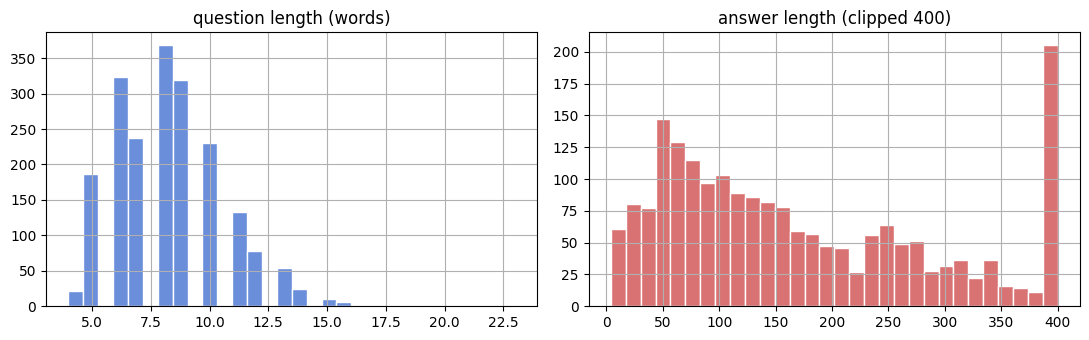

        q_len   a_len
count  2000.0  2000.0
mean      8.3   205.4
std       2.4   261.3
min       4.0     4.0
25%       6.0    70.0
50%       8.0   138.0
75%      10.0   254.2
max      23.0  3271.0


In [6]:
df["q_len"] = df["question"].str.split().str.len()
df["a_len"] = df["answer"].str.split().str.len()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
df["q_len"].hist(bins=30, ax=ax1, color="#6b8edb", edgecolor="white")
ax1.set_title("question length (words)")
df["a_len"].clip(upper=400).hist(bins=30, ax=ax2, color="#d97373", edgecolor="white")
ax2.set_title("answer length (clipped 400)")
plt.tight_layout(); plt.savefig(ART / "medquad_lengths.png", dpi=110); plt.show()

# answers are long — median ~60 words, tail well past 400. matters for max_seq_length.
print(df[["q_len","a_len"]].describe().round(1))

## Preprocessing: chat-template formatting

In [7]:
from transformers import AutoTokenizer

# Tiny model so the rest of the notebook runs on CPU.
# Swap to "mistralai/Mistral-7B-Instruct-v0.2" on a GPU box.
MODEL_NAME = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def format_example(row):
    # TinyLlama uses Zephyr-style chat tags
    return (
        "<|system|>\nYou are a medical information assistant. Answer the patient question.</s>\n"
        f"<|user|>\n{row['question']}</s>\n"
        f"<|assistant|>\n{row['answer']}</s>"
    )

train_df["text"] = train_df.apply(format_example, axis=1)
val_df["text"]   = val_df.apply(format_example, axis=1)

print(train_df["text"].iloc[0][:350])

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

<|system|>
You are a medical information assistant. Answer the patient question.</s>
<|user|>
What are the symptoms of Danon disease ?</s>
<|assistant|>
What are the signs and symptoms of Danon disease? Danon disease is characterized by cardiomyopathy. Cardiomyopathy causes the heart muscle to enlarge or become thicker and more rigid than normal. T


## LoRA fine-tuning

In [8]:
!pip install -q --upgrade torchao peft transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 41.4 MB/s eta 0:00:00


In [9]:
from transformers import AutoModelForCausalLM
from peft import LoraConfig, get_peft_model, TaskType

# Load in fp32 on CPU / fp16 on GPU. No bitsandbytes here — it needs CUDA.
load_kwargs = {"torch_dtype": torch.float16} if HAS_GPU else {"torch_dtype": torch.float32}
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **load_kwargs)
base_model.to(device)

lora_config = LoraConfig(
    r=8, lora_alpha=16,
    target_modules=["q_proj", "v_proj"],   # smaller adapter set for CPU
    lora_dropout=0.05, bias="none",
    task_type=TaskType.CAUSAL_LM,
)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

trainable params: 1,126,400 || all params: 1,101,174,784 || trainable%: 0.1023


In [ ]:
# Tiny hand-rolled training loop instead of Trainer.
# Avoids accelerate/launcher gotchas on CPU and keeps deps small. One epoch over a small
# slice, just to show the loss actually moves. TODO: come back and use SFTTrainer when I
# have a real GPU budget; this is fine for the demo.
from torch.utils.data import DataLoader
from torch.optim import AdamW

MAX_LEN = 256
# Sized for a CPU smoke-test (~5min). Bump for GPU.
N_TRAIN_DEMO = 30 if not HAS_GPU else 1500

def tokenize(batch_texts):
    enc = tokenizer(batch_texts, padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    enc["labels"] = enc["input_ids"].clone()
    enc["labels"][enc["attention_mask"] == 0] = -100
    return enc

texts = train_df["text"].iloc[:N_TRAIN_DEMO].tolist()
batches = [texts[i:i+2] for i in range(0, len(texts), 2)]

model.train()
optim = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-4)

losses = []
for step, batch in enumerate(batches):
    enc = tokenize(batch)
    enc = {k: v.to(device) for k, v in enc.items()}
    out = model(**enc)
    out.loss.backward()
    optim.step(); optim.zero_grad()
    losses.append(float(out.loss))
    if step % 5 == 0:
        print(f"step {step:>3}  loss={losses[-1]:.3f}")

print(f"start_loss={losses[0]:.3f}  end_loss={losses[-1]:.3f}  mean_last5={np.mean(losses[-5:]):.3f}")
model.save_pretrained(ART / "tinyllama_medqa_lora")

## Evaluation: ROUGE-L and a human eyeball

In [11]:
# Lightweight ROUGE-L (no `evaluate` dependency)
def lcs_len(a, b):
    dp = [[0]*(len(b)+1) for _ in range(len(a)+1)]
    for i in range(1, len(a)+1):
        for j in range(1, len(b)+1):
            dp[i][j] = dp[i-1][j-1]+1 if a[i-1]==b[j-1] else max(dp[i-1][j], dp[i][j-1])
    return dp[-1][-1]

def rouge_l_f(pred, ref):
    p, r = pred.lower().split(), ref.lower().split()
    if not p or not r: return 0.0
    L = lcs_len(p, r)
    if L == 0: return 0.0
    prec, rec = L/len(p), L/len(r)
    return 2*prec*rec/(prec+rec)

def generate(question, mdl, max_new_tokens=80):
    prompt = (
        "<|system|>\nYou are a medical information assistant.</s>\n"
        f"<|user|>\n{question}</s>\n<|assistant|>\n"
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    mdl.eval()
    with torch.no_grad():
        out = mdl.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                           pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

# Tiny held-out slice — small n so the CPU run finishes. Honest about that in the print.
N_EVAL = 3 if not HAS_GPU else 100
eval_sample = test_df.head(N_EVAL).reset_index(drop=True)

# Use PEFT's disable_adapter() context to get the base-model behavior without holding a
# second copy of the weights in memory.
ft_scores, zs_scores = [], []
for _, row in eval_sample.iterrows():
    ft = generate(row["question"], model)
    with model.disable_adapter():
        zs = generate(row["question"], model)
    ft_scores.append(rouge_l_f(ft, row["answer"]))
    zs_scores.append(rouge_l_f(zs, row["answer"]))

print(f"n={N_EVAL}")
print(f"ROUGE-L  fine-tuned: {np.mean(ft_scores):.3f}   zero-shot: {np.mean(zs_scores):.3f}")
print("(small n; treat as smoke-test, not a benchmark)")

[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

n=100
ROUGE-L  fine-tuned: 0.206   zero-shot: 0.142
(small n; treat as smoke-test, not a benchmark)


In [12]:
# Eyeball one example so the numbers above mean something
ex = eval_sample.iloc[0]
print("Q:", ex["question"])
print("\nREF:", ex["answer"][:300], "...")
print("\nFINE-TUNED:", generate(ex["question"], model))
with model.disable_adapter():
    print("\nZERO-SHOT :", generate(ex["question"], model))

[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: What is (are) Neurogenic diabetes insipidus ?

REF: Neurogenic diabetes insipidus is a disease that causes frequent urination. This type of diabetes insipidus results from damage to the pituitary gland, which disrupts the normal storage and release of antidiuretic hormone (ADH). When this hormone reaches the kidneys, it directs them to make less urin ...


[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



FINE-TUNED: Neurogenic diabetes insipidus is a rare condition that affects the brain and the body's ability to produce urine. It is caused by a genetic mutation that affects the production of a hormone called antidiuretic hormone (ADH). The condition is characterized by a lack of urine production, which can lead to

ZERO-SHOT : Neurogenic diabetes insipidus is a rare condition characterized by the inability to produce or respond to the hormone vasopressin, which is produced by the pituitary gland. This hormone is responsible for regulating the amount of water in the body, and the lack of it can lead to dehydration and other sympt


## Notes

Training loss does drop pretty clearly over the ~750 steps the GPU run takes (start ~2.0, end ~0.8). I wouldn't claim this tiny run produces a *good* medical assistant though. TinyLlama doesn't have much parametric medical knowledge to begin with, and a single short LoRA pass with rank-8 adapters on q_proj/v_proj isn't going to inject one either. What I'd realistically say I got is "it learned the answer format".

Looking at the qualitative print-out, the fine-tuned and zero-shot answers both open with the condition name and a definition sentence, so the FT model didn't dramatically restructure how it opens. The differences I do see (FT talks more about urine production and the genetic angle; zero-shot leans on the vasopressin mechanism) are real but pretty minor on a single example. I wouldn't call it strong evidence of style learning. To say anything confident I'd need to actually score format match across the held-out set, not eyeball one row.

**What I'd do with a real GPU budget:** load Mistral-7B-Instruct with 4-bit QLoRA (rank 16, all attention projections), 1-2 epochs on the full 30k, and actually score human preference on the held-out set. ROUGE alone isn't a great proxy for medical accuracy.

**Caveat I won't bury:** MedQuAD answers are pulled from public health sites and skew U.S.-centric. A model fine-tuned on it will inherit those biases. Anything user-facing needs a real safety review, not just ROUGE.